# RFM và phân khúc giá trị khách hàng — Online Retail II
## Phần A: RFM trên toàn bộ dữ liệu. Phần B: RFM theo từng tuần

**Câu hỏi kinh doanh:** Nên ưu tiên khách hàng nào cho hoạt động giữ chân hoặc khuyến mãi để tăng biên lợi nhuận kỳ vọng trong tương lai mà không giảm giá quá mức?

**Đầu vào:** `clean_transactions.csv` do `00_data_cleaning.ipynb` tạo ra.

**Notebook này không dùng cutoff cố định, không dùng cửa sổ quan sát và không có nhãn tương lai.**

| | Phần A: toàn bộ dữ liệu | Phần B: theo từng tuần |
|---|---|---|
| **Cách tính** | R, F, M trên **toàn bộ lịch sử** của mỗi khách. R tính đến ngày sau giao dịch cuối cùng của dữ liệu | Mỗi thứ Hai là một mốc. R, F, M **tính đến mốc đó**, và thêm F, M **chỉ của riêng tuần đó** |
| **Một dòng là** | Một khách | Một khách tại một tuần |
| **Dùng để** | Hồ sơ nhóm hiện tại, Pareto, cohort | Xem từng khách đổi nhóm như thế nào theo thời gian |Ư

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

clean = pd.read_csv("clean_transactions.csv", parse_dates=["InvoiceDate"],
                    usecols=["Invoice", "InvoiceDate", "Revenue", "CustomerID", "is_return"], dtype={"Invoice": str})
clean = clean.dropna(subset=["CustomerID"]).astype({"CustomerID": int})
first_seen = clean.groupby("CustomerID")["InvoiceDate"].min()

DATA_START = clean["InvoiceDate"].min().normalize()
END = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)   # the day after the last transaction
print(f"{len(clean):,} rows | {clean['CustomerID'].nunique():,} customers | {DATA_START.date()} to {END.date()} (exclusive)")

SEGMENTS = ["Champions", "VIP at risk", "Loyal", "Developing", "One-time recent", "Cooling", "Lapsed", "Dormant"]
T = {"recency_active": 90, "recency_lapsed": 180, "recency_dormant": 365, "freq_repeat": 2, "freq_loyal": 4}

def assign_segment(r, monetary_high):
    high_value = r["monetary"] >= monetary_high
    active = r["recency_days"] <= T["recency_active"]
    conditions = [
        high_value & active,
        high_value,
        active & (r["frequency"] >= T["freq_loyal"]),
        active & (r["frequency"] >= T["freq_repeat"]),
        active,
        r["recency_days"] <= T["recency_lapsed"],
        r["recency_days"] <= T["recency_dormant"],
    ]
    seg = np.select(conditions, SEGMENTS[:-1], default=SEGMENTS[-1])
    return pd.Categorical(seg, categories=SEGMENTS, ordered=True)

794,165 rows | 5,875 customers | 2009-12-01 to 2011-12-10 (exclusive)


# Phần A. RFM trên toàn bộ dữ liệu

## 8. Đặc trưng RFM

### 8.1 Định nghĩa

| Đặc trưng | Định nghĩa | Lý do |
|---|---|---|
| `recency_days` (R) | Số ngày từ lần **mua** cuối đến ngày sau giao dịch cuối của dữ liệu | Hóa đơn trả hàng không tính là hoạt động mua |
| `frequency` (F) | Số hóa đơn bán khác nhau trong toàn bộ lịch sử | Khớp với mốc 1 / 2-3 / 4+ ở mục 6.13 |
| `monetary` (M) | Doanh số bán trừ hàng trả trong toàn bộ lịch sử, sàn ở 0 | Hàng trả làm hao hụt giá trị thật của khách |
| `purchase_days` | Số ngày mua khác nhau | Đối chiếu với F (khách bán buôn có thể xuất nhiều hóa đơn trong một ngày) |
| `avg_order_value` | Doanh số bán / F | Phân biệt khách đơn lớn với khách đơn nhỏ |
| `return_rate` | Giá trị hàng trả / doanh số bán | Hàng trả làm hao hụt biên lợi nhuận |
| `tenure_days` | Số ngày từ lần đầu xuất hiện đến ngày tính | Khách lâu năm hay khách mới |
| `avg_gap_days` | Số ngày trung bình giữa hai ngày mua liên tiếp (rỗng nếu chỉ mua một ngày) | Nhịp mua riêng của từng khách |
| `recency_gap_ratio` | `recency_days` / `avg_gap_days` | Khách có nhịp 30 ngày mà đã 80 ngày không mua đáng lo hơn khách có nhịp 150 ngày. Tỷ số > 1 nghĩa là đã im lặng lâu hơn nhịp thường lệ |
| `frequency_90d`, `monetary_90d` | F và M chỉ tính 90 ngày cuối | Hoạt động gần đây, nhạy hơn số liệu toàn lịch sử |
| `monetary_90d_share` | `monetary_90d` / `monetary` | Khách đang tăng hay giảm hoạt động so với mức toàn lịch sử |

Các cột nhịp mua và 90 ngày **không dùng để phân nhóm**, chỉ để mô tả khách chi tiết hơn.

**Lưu ý:** vì F và M cộng dồn toàn lịch sử nên chúng chỉ tăng theo thời gian. Khách có mặt từ 2009-12 có nhiều thời gian để tích lũy hơn khách mới, nên F và M ở phần A phản ánh một phần độ dài lịch sử của khách.

In [2]:
def build_rfm(rows, ref_date):
    sales = rows[~rows["is_return"]]
    returns = rows[rows["is_return"]]
    g = sales.groupby("CustomerID")

    rfm = pd.DataFrame({
        "recency_days": (ref_date - g["InvoiceDate"].max()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "purchase_days": g["InvoiceDate"].apply(lambda d: d.dt.normalize().nunique()),
        "gross_sales": g["Revenue"].sum(),
    })
    rfm["return_value"] = -returns.groupby("CustomerID")["Revenue"].sum()
    rfm["return_value"] = rfm["return_value"].fillna(0)
    rfm["monetary"] = (rfm["gross_sales"] - rfm["return_value"]).clip(lower=0)
    rfm["avg_order_value"] = rfm["gross_sales"] / rfm["frequency"]
    rfm["return_rate"] = rfm["return_value"] / rfm["gross_sales"]
    rfm["tenure_days"] = (ref_date - first_seen.reindex(rfm.index)).dt.days

    # Purchase rhythm: mean gap between distinct purchase days, and how long the customer has been silent relative to it
    days = sales.assign(day=sales["InvoiceDate"].dt.normalize()).groupby("CustomerID")["day"]
    rfm["avg_gap_days"] = (days.max() - days.min()).dt.days / (rfm["purchase_days"] - 1).replace(0, np.nan)
    rfm["recency_gap_ratio"] = rfm["recency_days"] / rfm["avg_gap_days"]

    # Short window: last 90 days before ref_date
    last90 = ref_date - pd.Timedelta(days=90)
    g90 = sales[sales["InvoiceDate"] >= last90].groupby("CustomerID")
    ret90 = returns[returns["InvoiceDate"] >= last90].groupby("CustomerID")["Revenue"].sum()
    gross90 = g90["Revenue"].sum()
    rfm["frequency_90d"] = g90["Invoice"].nunique().reindex(rfm.index).fillna(0).astype(int)
    rfm["monetary_90d"] = (gross90 + ret90.reindex(gross90.index).fillna(0)).clip(lower=0).reindex(rfm.index).fillna(0)
    rfm["monetary_90d_share"] = rfm["monetary_90d"] / rfm["monetary"].replace(0, np.nan)
    return rfm.reset_index()

rfm = build_rfm(clean, END)
assert rfm[["recency_days", "frequency", "monetary"]].notna().all().all()
print(f"{len(rfm):,} customers with at least one sale")

rfm[["recency_days", "frequency", "purchase_days", "monetary", "avg_order_value", "return_rate", "tenure_days",
     "avg_gap_days", "recency_gap_ratio", "frequency_90d", "monetary_90d", "monetary_90d_share"]] \
    .describe(percentiles=[.25, .5, .75, .9, .95, .99])

5,852 customers with at least one sale


,recency_days,frequency,purchase_days,monetary,avg_order_value,return_rate,tenure_days,avg_gap_days,recency_gap_ratio,frequency_90d,monetary_90d,monetary_90d_share
count,"5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","5,852.00","4,179.00","4,179.00","5,852.00","5,852.00","5,833.00"
mean,199.73,6.25,5.62,"2,795.90",384.40,0.02,475.66,111.48,3.75,1.12,534.36,0.22
std,208.52,12.75,9.92,"13,825.20","1,254.73",0.10,224.35,102.34,22.37,2.51,"3,020.71",0.32
min,0.00,1.00,1.00,0.00,2.95,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,25.00,1.00,1.00,330.94,176.15,0.00,313.00,44.00,0.22,0.00,0.00,0.00
50%,95.00,3.00,3.00,840.25,277.87,0.00,532.00,80.00,0.64,0.00,0.00,0.00
75%,379.00,7.00,6.00,"2,172.03",410.56,0.01,670.00,142.00,2.14,1.00,474.06,0.30
90%,530.00,13.00,12.00,"5,224.45",624.03,0.05,731.00,238.20,6.23,3.00,"1,131.14",1.00
95%,623.00,20.00,18.45,"8,899.83",871.21,0.10,736.00,348.00,12.79,4.00,"1,849.46",1.00
99%,726.00,46.00,39.00,"26,490.31","1,907.11",0.39,738.00,513.22,37.34,9.00,"4,813.24",1.00


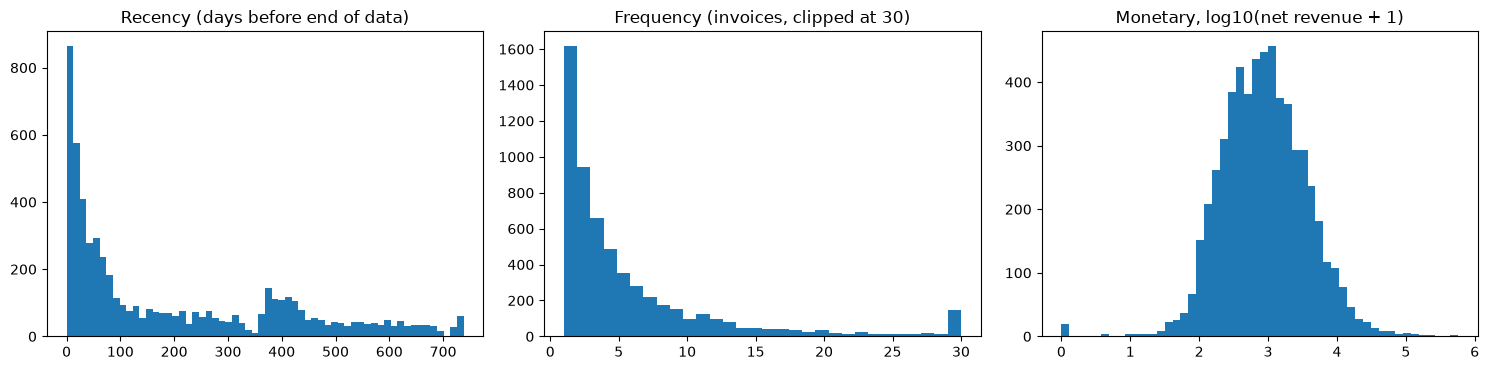

Share of customers with F != purchase_days: 20.8%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(rfm["recency_days"], bins=60, color="tab:blue")
axes[1].hist(rfm["frequency"].clip(upper=30), bins=30, color="tab:blue")
axes[2].hist(np.log10(rfm["monetary"] + 1), bins=50, color="tab:blue")
axes[0].set_title("Recency (days before end of data)")
axes[1].set_title("Frequency (invoices, clipped at 30)")
axes[2].set_title("Monetary, log10(net revenue + 1)")
plt.tight_layout(); plt.show()

print(f"Share of customers with F != purchase_days: {(rfm['frequency'] != rfm['purchase_days']).mean():.1%}")

**Ý nghĩa của "Share of customers with F != purchase_days" (20.8%):** đây là tỷ lệ khách có số hóa đơn (F) lớn hơn số ngày mua khác nhau (`purchase_days`), tức là khách có **nhiều hóa đơn trong cùng một ngày**.

* F đếm số hóa đơn; `purchase_days` đếm số ngày khác nhau có mua. Hai số bằng nhau khi mỗi ngày khách chỉ có một hóa đơn.
* Ví dụ: khách mua vào thứ Hai và có hai hóa đơn (một cho hàng khô, một cho hàng đông lạnh) thì F tăng 2 nhưng chỉ có 1 ngày mua.
* Khách bán buôn thường tách đơn như vậy (theo nhà kho hoặc theo loại hàng), nên F của họ có thể cao hơn số lần quay lại thật sự. Khách có F = 4 chưa chắc đã quay lại 4 lần.
* Notebook vẫn dùng **F theo hóa đơn** trong luật phân nhóm, để khớp với các mốc 1 / 2-3 / 4+ ở mục 6.13. Cột `purchase_days` được giữ lại để đối chiếu. Nếu muốn F phản ánh số lần quay lại, có thể thay F bằng `purchase_days` trong luật; một số khách Loyal khi đó sẽ xuống Developing.

### 8.2 Đặt ngưỡng

Mỗi ngưỡng có một nguồn bằng chứng:
* **R:** mốc 90 ngày và 180 ngày từ mục 6.9 (71% khách có trung vị khoảng cách mua ≤ 90 ngày, 93% ≤ 180 ngày). Quá 90 ngày là khách bắt đầu "nguội", quá 180 ngày là đã vắng lâu. Mốc **365 ngày** (một năm không mua) tách khách quá 180 ngày thành hai nhóm: Lapsed (181-365) và Dormant (> 365).
* **F:** mốc 1 / 2-3 / 4+ hóa đơn từ mục 6.13.
* **M:** đường cong tập trung doanh thu (Pareto). Ngưỡng "giá trị cao" là mức doanh thu của top 10% khách.

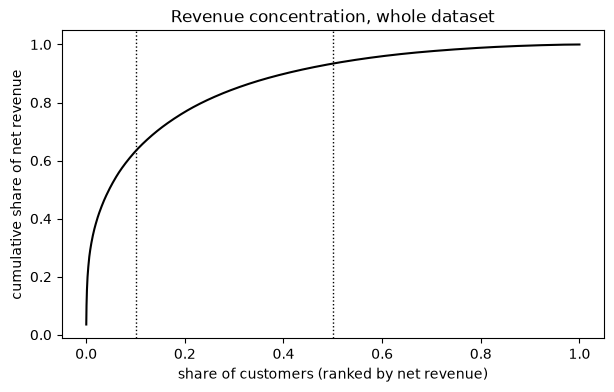

monetary_high (top 10%) = 5,224.45


,monetary_threshold,share_of_revenue
customers,,
top 1%,"26,679.24",0.31
top 5%,"8,945.53",0.51
top 10%,"5,250.78",0.63
top 20%,"2,835.36",0.77
top 30%,"1,743.15",0.85
top 50%,840.25,0.93


In [4]:
m = rfm["monetary"].sort_values(ascending=False).reset_index(drop=True)
cum_share = m.cumsum() / m.sum()
qs = (.01, .05, .10, .20, .30, .50)
pareto = pd.DataFrame({
    "monetary_threshold": [m.iloc[int(len(m) * q) - 1] for q in qs],
    "share_of_revenue": [cum_share.iloc[int(len(m) * q) - 1] for q in qs],
}, index=pd.Index(["top 1%", "top 5%", "top 10%", "top 20%", "top 30%", "top 50%"], name="customers"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(m) + 1) / len(m), cum_share, color="black")
for q in (.1, .5):
    ax.axvline(q, color="k", ls=":", lw=1)
ax.set_xlabel("share of customers (ranked by net revenue)"); ax.set_ylabel("cumulative share of net revenue")
ax.set_title("Revenue concentration, whole dataset"); plt.show()

MONETARY_HIGH = rfm["monetary"].quantile(.90)
print(f"monetary_high (top 10%) = {MONETARY_HIGH:,.2f}")
pareto

### 8.3 Luật phân nhóm

Các điều kiện được xét **theo thứ tự**: khách rơi vào điều kiện đầu tiên đúng. Nhờ vậy các nhóm loại trừ nhau và phủ hết mọi khách (8 nhóm).

| # | Nhóm | Điều kiện | Ý nghĩa |
|---|---|---|---|
| 1 | Champions | M ≥ top 10% **và** R ≤ 90 | Giá trị cao nhất, đang hoạt động |
| 2 | VIP at risk | M ≥ top 10% **và** R > 90 | Từng giá trị cao nhưng đã lâu không mua |
| 3 | Loyal | R ≤ 90 **và** F ≥ 4 | Mua đều, giá trị vừa |
| 4 | Developing | R ≤ 90 **và** F = 2-3 | Đã mua lại, chưa thành thói quen |
| 5 | One-time recent | R ≤ 90 **và** F = 1 | Mới mua một lần gần đây |
| 6 | Cooling | 90 < R ≤ 180 | Đang nguội |
| 7 | Lapsed | 180 < R ≤ 365 | Đã vắng lâu nhưng còn cơ hội kéo lại |
| 8 | Dormant | R > 365 | Gần như đã rời đi |

In [5]:
rfm["segment"] = assign_segment(rfm, MONETARY_HIGH)
assert rfm["segment"].notna().all()

rfm["segment"].value_counts().reindex(SEGMENTS).rename("customers").to_frame()

,customers
segment,
Champions,515
VIP at risk,71
Loyal,1345
Developing,658
One-time recent,367
Cooling,555
Lapsed,777
Dormant,1564


### 8.4 Hồ sơ nhóm

Với mỗi nhóm: quy mô, đặc điểm (R, F, M, trả hàng, nhịp mua) và phần đóng góp vào doanh thu.

In [6]:
profile = rfm.groupby("segment", observed=False).agg(
    customers=("CustomerID", "size"),
    median_recency=("recency_days", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median"),
    mean_monetary=("monetary", "mean"),
    median_return_rate=("return_rate", "median"),
    median_avg_gap_days=("avg_gap_days", "median"),
    median_monetary_90d=("monetary_90d", "median"),
    total_monetary=("monetary", "sum"),
)
profile.insert(1, "share_customers", profile["customers"] / profile["customers"].sum())
profile["share_revenue"] = profile.pop("total_monetary") / rfm["monetary"].sum()
profile

,customers,share_customers,median_recency,median_frequency,median_monetary,mean_monetary,median_return_rate,median_avg_gap_days,median_monetary_90d,share_revenue
segment,,,,,,,,,,
Champions,515,0.09,11.00,20.00,"8,945.53","18,449.48",0.01,37.53,"1,551.72",0.58
VIP at risk,71,0.01,184.00,13.00,"8,550.92","11,978.52",0.01,43.02,0.00,0.05
Loyal,1345,0.23,24.00,7.00,"2,070.71","2,294.74",0.00,79.44,474.02,0.19
Developing,658,0.11,29.00,2.00,663.66,805.98,0.00,164.75,347.52,0.03
One-time recent,367,0.06,44.00,1.00,256.32,368.84,0.00,NaN,256.32,0.01
Cooling,555,0.09,131.00,3.00,868.77,"1,241.88",0.00,106.70,0.00,0.04
Lapsed,777,0.13,260.00,2.00,566.13,870.61,0.00,107.67,0.00,0.04
Dormant,1564,0.27,468.00,1.00,338.56,570.21,0.00,74.50,0.00,0.05


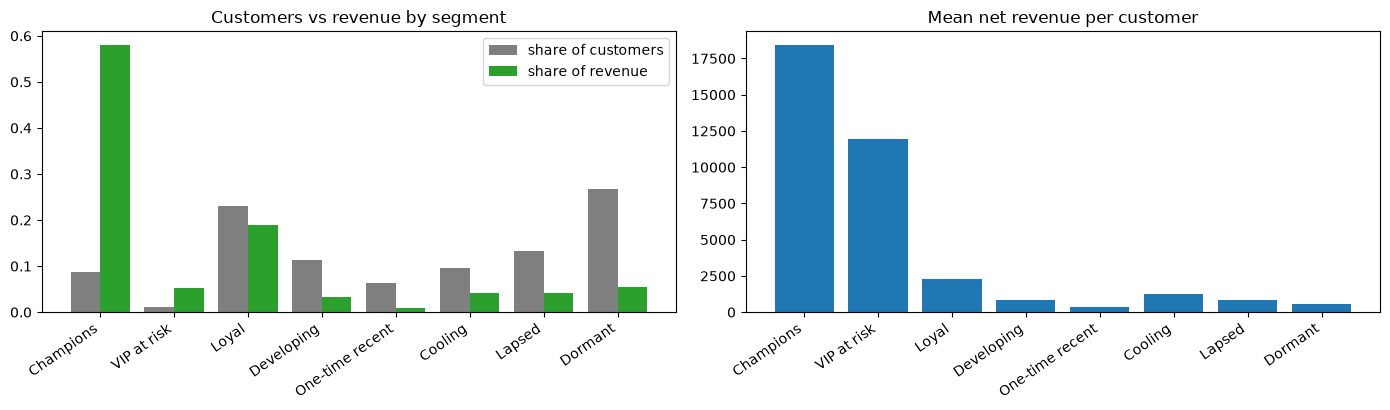

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(SEGMENTS))
axes[0].bar(x - .2, profile["share_customers"], width=.4, color="tab:gray", label="share of customers")
axes[0].bar(x + .2, profile["share_revenue"], width=.4, color="tab:green", label="share of revenue")
axes[0].set_title("Customers vs revenue by segment")
axes[1].bar(x, profile["mean_monetary"], color="tab:blue")
axes[1].set_title("Mean net revenue per customer")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(SEGMENTS, rotation=35, ha="right")
axes[0].legend()
plt.tight_layout(); plt.show()

### 8.5 Cohort view: giữ chân theo tháng mua đầu tiên

Mỗi cohort là nhóm khách có lần mua đầu tiên trong cùng một tháng. Ô (cohort, k) là tỷ lệ khách của cohort đó có mua trong tháng thứ k sau tháng đầu tiên.

**Lưu ý:**
* Dữ liệu bắt đầu từ 2009-12, nên cohort 2009-12 gồm cả khách đã mua từ trước đó, và tỷ lệ giữ chân của cohort này cao hơn thực tế của một cohort khách mới.
* Tháng 2011-12 chỉ có dữ liệu đến ngày 9, nên ô cuối cùng của mỗi hàng (đường chéo cuối của ma trận) thấp hơn thực tế.

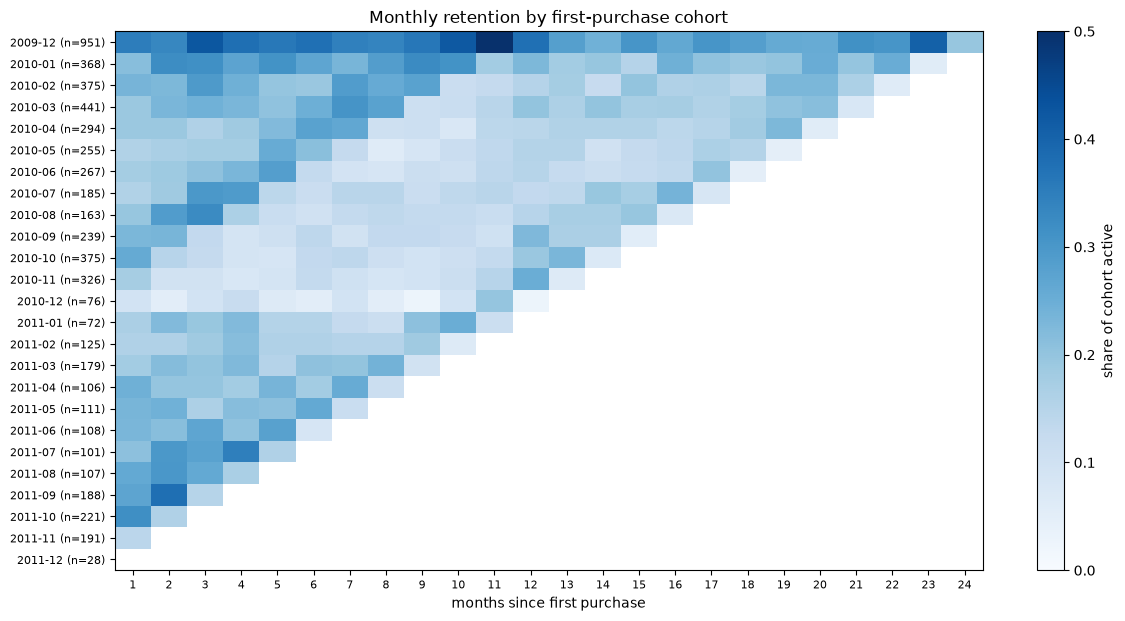

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2009-12,1.00,0.35,0.33,0.42,0.38,0.36,0.38,0.34,0.34,0.36,0.42,0.50,0.38
2010-01,1.00,0.21,0.32,0.32,0.27,0.31,0.27,0.23,0.29,0.33,0.31,0.18,0.23
2010-02,1.00,0.23,0.23,0.29,0.25,0.20,0.19,0.29,0.26,0.28,0.11,0.13,0.15
2010-03,1.00,0.19,0.23,0.24,0.23,0.20,0.25,0.31,0.28,0.11,0.12,0.15,0.20
2010-04,1.00,0.19,0.19,0.16,0.18,0.22,0.28,0.27,0.11,0.11,0.07,0.14,0.14
2010-05,1.00,0.16,0.17,0.18,0.18,0.25,0.21,0.13,0.06,0.08,0.11,0.13,0.15
2010-06,1.00,0.18,0.19,0.21,0.23,0.28,0.13,0.09,0.08,0.11,0.10,0.14,0.15
2010-07,1.00,0.16,0.18,0.30,0.29,0.14,0.11,0.15,0.15,0.11,0.14,0.15,0.13
2010-08,1.00,0.20,0.29,0.33,0.17,0.12,0.10,0.13,0.13,0.13,0.13,0.12,0.15


In [8]:
active = clean[~clean["is_return"]].assign(month=lambda d: d["InvoiceDate"].dt.to_period("M"))[["CustomerID", "month"]].drop_duplicates()
active["cohort"] = active.groupby("CustomerID")["month"].transform("min")
active["months_since_first"] = (active["month"] - active["cohort"]).apply(lambda p: p.n)

counts = active.pivot_table(index="cohort", columns="months_since_first", values="CustomerID", aggfunc="nunique")
retention = counts.div(counts[0], axis=0)

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(retention.iloc[:, 1:].values, aspect="auto", cmap="Blues", vmin=0, vmax=.5)
ax.set_yticks(range(len(retention))); ax.set_yticklabels([f"{c} (n={int(n):,})" for c, n in counts[0].items()], fontsize=8)
ax.set_xticks(range(retention.shape[1] - 1)); ax.set_xticklabels(retention.columns[1:], fontsize=8)
ax.set_xlabel("months since first purchase"); ax.set_title("Monthly retention by first-purchase cohort")
fig.colorbar(im, ax=ax, label="share of cohort active"); plt.show()
retention.iloc[:, :13]

In [9]:
# Average retention curve, weighting each cohort by size; excluding the left-censored 2009-12 cohort
c = counts[counts.index > pd.Period("2009-12", "M")]
observed_size = c.notna().mul(c[0], axis=0).sum()          # only cohorts old enough to reach month k
avg_curve = c.sum() / observed_size
avg_curve.iloc[:13].rename("weighted retention, cohorts from 2010-01").to_frame().T

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
"weighted retention, cohorts from 2010-01",1.00,0.21,0.21,0.21,0.19,0.19,0.18,0.18,0.16,0.15,0.13,0.14,0.18


# Phần B. RFM theo từng tuần

Mỗi **thứ Hai** là một mốc. Tại mỗi mốc, với mọi khách đã mua trước đó, ta tính:
* `recency_days`, `frequency`, `monetary`: **tính đến mốc đó**, dùng toàn bộ lịch sử trước mốc (cộng dồn). Đây là phần dùng để gán nhóm.
* `frequency_week`, `monetary_week`: **chỉ của riêng 7 ngày trước mốc**, không cộng dồn. Đây là hoạt động thật của khách trong tuần đó.

**Vì sao nhóm phải dùng số liệu cộng dồn, không dùng riêng từng tuần:** trong một tuần bất kỳ chỉ khoảng 8% khách mua hàng, và gần 90% khách có mua chỉ có một hóa đơn trong tuần đó (xem mục 9.5). Từng tuần tách riêng quá thưa để có R, F, M và phân nhóm. Phần B vẫn giữ riêng số liệu từng tuần để xem nhịp mua.

Ngưỡng M cao được tính lại mỗi tuần (top 10% M cộng dồn của khách đã mua đến lúc đó), vì M cộng dồn chỉ tăng theo thời gian. Các mốc R và F giữ nguyên như phần A.

In [10]:
WEEKS = pd.date_range(DATA_START + pd.offsets.Week(weekday=0), END - pd.Timedelta(days=1), freq="W-MON")
print(f"{len(WEEKS)} weekly snapshots {WEEKS[0].date()} -> {WEEKS[-1].date()}")

rows, m_high_by_week = [], {}
for cutoff in WEEKS:
    w = clean[clean["InvoiceDate"] < cutoff]
    sales, rets = w[~w["is_return"]], w[w["is_return"]]
    g = sales.groupby("CustomerID")
    r = pd.DataFrame({"recency_days": (cutoff - g["InvoiceDate"].max()).dt.days,
                      "frequency": g["Invoice"].nunique(), "gross_sales": g["Revenue"].sum()})
    r["return_value"] = (-rets.groupby("CustomerID")["Revenue"].sum()).reindex(r.index).fillna(0)
    r["monetary"] = (r["gross_sales"] - r["return_value"]).clip(lower=0)

    # This week only (7 days before the snapshot), not cumulative
    wk = w[w["InvoiceDate"] >= cutoff - pd.Timedelta(days=7)]
    wk_sales = wk[~wk["is_return"]]
    r["frequency_week"] = wk_sales.groupby("CustomerID")["Invoice"].nunique().reindex(r.index).fillna(0).astype(int)
    r["monetary_week"] = wk.groupby("CustomerID")["Revenue"].sum().reindex(r.index).fillna(0).clip(lower=0)

    m_high_by_week[cutoff] = r["monetary"].quantile(.90)
    r["segment"] = assign_segment(r, m_high_by_week[cutoff])
    r.insert(0, "snapshot_date", cutoff)
    rows.append(r.rename_axis("CustomerID").reset_index())

weekly = pd.concat(rows, ignore_index=True).drop(columns=["gross_sales", "return_value"])
weekly["segment"] = pd.Categorical(weekly["segment"], categories=SEGMENTS, ordered=True)
print(f"{len(weekly):,} rows | {weekly['CustomerID'].nunique():,} customers")
weekly.head()

105 weekly snapshots 2009-12-07 -> 2011-12-05


394,694 rows | 5,835 customers


,CustomerID,snapshot_date,recency_days,frequency,monetary,frequency_week,monetary_week,segment
0,12359,2009-12-07,1,1,760.69,1,760.69,One-time recent
1,12417,2009-12-07,0,1,279.10,1,279.10,One-time recent
2,12435,2009-12-07,4,1,"1,008.00",1,"1,008.00",Champions
3,12437,2009-12-07,4,1,524.28,1,524.28,One-time recent
4,12490,2009-12-07,5,1,531.94,1,531.94,One-time recent


### 9.1 Số khách mỗi nhóm theo tuần và ngưỡng M cao

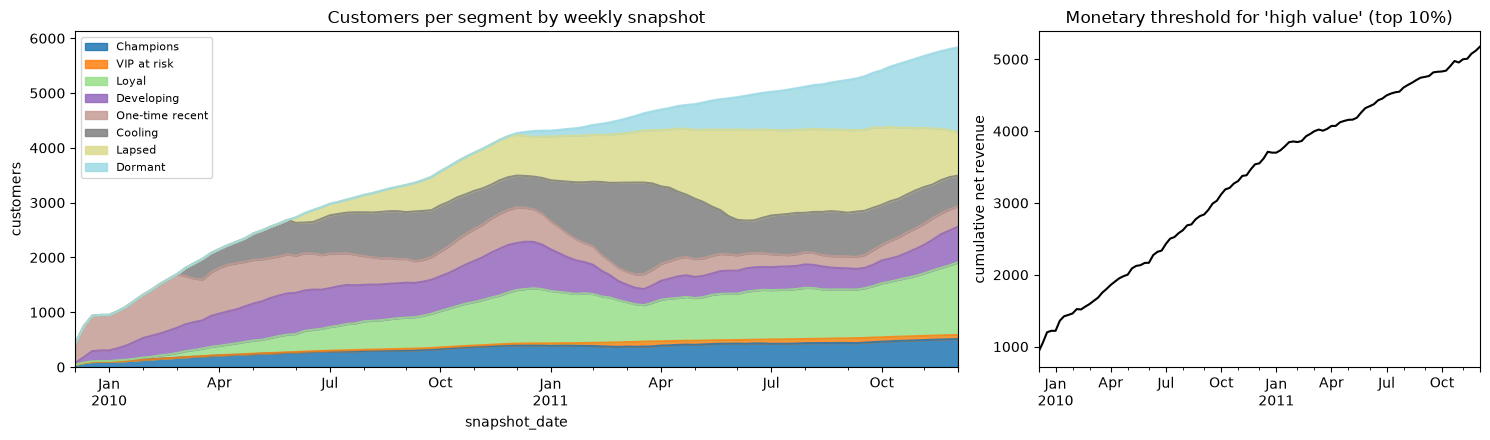

segment,Champions,VIP at risk,Loyal,Developing,One-time recent,Cooling,Lapsed,Dormant
snapshot_date,,,,,,,,
2009-12-07,43,0,2,31,349,0,0,0
2010-02-15,152,0,60,400,905,0,0,0
2010-07-05,285,13,433,709,629,699,211,0
2010-12-06,396,31,978,858,652,579,747,28
2011-06-20,431,67,895,427,260,598,1650,652
2011-12-05,513,71,1328,649,377,556,791,1550


In [11]:
seg_counts = weekly.groupby(["snapshot_date", "segment"], observed=False).size().unstack()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
seg_counts.plot.area(ax=axes[0], colormap="tab20", alpha=.85)
axes[0].set_ylabel("customers"); axes[0].set_title("Customers per segment by weekly snapshot")
axes[0].legend(loc="upper left", fontsize=8)
pd.Series(m_high_by_week).plot(ax=axes[1], color="black")
axes[1].set_title("Monetary threshold for 'high value' (top 10%)"); axes[1].set_ylabel("cumulative net revenue")
plt.tight_layout(); plt.show()
seg_counts.iloc[[0, 10, 30, 52, 80, -1]]

**Nhận xét biểu đồ:**

| # | Phát hiện | Bằng chứng | Ý nghĩa |
|---|---|---|---|
| 1 | Tổng số khách chỉ tăng, không giảm | 4,269 khách (2010-12-06) lên 5,835 (2011-12-05) | Khách đã mua thì ở lại bảng mãi mãi. Chiều cao tổng là số khách đã từng mua, không phải số khách đang hoạt động |
| 2 | Dormant và Lapsed phình ra theo thời gian | Dormant: 28 (2010-12-06), 590 (2011-06-06), 1,550 (2011-12-05), tức 27% tổng. Lapsed: 747, 1,650, 791 | Đây là lịch sử cộng dồn, không phải dấu hiệu tình hình xấu đi. Khó so Dormant của hai thời điểm khác nhau |
| 3 | Cooling tăng vọt sau mùa Q4 rồi xẹp | Từ 579 (2010-12-06) lên đỉnh 1,679 (2011-03-14), rồi còn 646 (2011-06-06) | Khách mua trong mùa cao điểm nguội dần qua mốc 90 ngày, rồi qua 180 và 365 ngày và chuyển hẳn sang Lapsed, Dormant |
| 4 | One-time recent và Developing teo lại sau Q4 | One-time recent từ 652 xuống 244 (2011-03-14); Developing từ 858 xuống 299 | Khách mới của mùa Q4 không quay lại sau 90 ngày |
| 5 | Champions và Loyal tăng đều | Champions từ 396 lên 513; Loyal từ 978 lên 1,328 (2010-12-06 → 2011-12-05) | Nhóm khách giá trị nhất ít chịu ảnh hưởng mùa vụ |
| 6 | VIP at risk nhỏ nhưng dao động theo mùa | 31 (2010-12-06), đỉnh 88 (2011-03-14), 71 (2011-12-05) | Khách giá trị cao vắng quá 90 ngày sau mùa cao điểm, một phần quay lại Champions |
| 7 | Ngưỡng M cao tăng gần tuyến tính | Từ khoảng 1,000 lên khoảng 5,200 | M cộng dồn chỉ tăng nên phải tính lại ngưỡng mỗi tuần |

### 9.2 Quỹ đạo nhóm của từng khách
Mỗi dòng là một khách, mỗi cột là một tuần. Ô trống nghĩa là khách chưa từng mua tính đến tuần đó.

In [12]:
wide = weekly.pivot(index="CustomerID", columns="snapshot_date", values="segment")
wide.columns = [c.strftime("%Y-%m-%d") for c in wide.columns]
wide.iloc[:5, -8:]

,2011-10-17,2011-10-24,2011-10-31,2011-11-07,2011-11-14,2011-11-21,2011-11-28,2011-12-05
CustomerID,,,,,,,,
12346,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed
12347,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal
12348,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal,Loyal
12349,Lapsed,Lapsed,Dormant,Dormant,Dormant,Dormant,Developing,Developing
12350,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed,Lapsed


### 9.3 Chuyển nhóm giữa hai tuần liền kề
Chỉ tính khách có mặt ở cả hai tuần. Mỗi hàng chuẩn hóa về 100%: hàng là nhóm tuần trước, cột là nhóm tuần sau.

In [13]:
trans = []
for a, b in zip(wide.columns[:-1], wide.columns[1:]):
    pair = wide[[a, b]].dropna()
    trans.append(pd.DataFrame({"from_segment": pair[a].values, "to_segment": pair[b].values}))
trans = pd.concat(trans, ignore_index=True)
tm = pd.crosstab(trans["from_segment"], trans["to_segment"])
tm.div(tm.sum(axis=1), axis=0)

to_segment,Champions,VIP at risk,Loyal,Developing,One-time recent,Cooling,Lapsed,Dormant
from_segment,,,,,,,,
Champions,0.97,0.01,0.01,0.00,0.00,0.00,0.00,0.00
VIP at risk,0.07,0.92,0.00,0.00,0.00,0.01,0.00,0.00
Loyal,0.01,0.00,0.96,0.00,0.00,0.03,0.00,0.00
Developing,0.00,0.00,0.03,0.92,0.00,0.05,0.00,0.00
One-time recent,0.00,0.00,0.00,0.04,0.90,0.05,0.00,0.00
Cooling,0.00,0.00,0.02,0.02,0.00,0.90,0.06,0.00
Lapsed,0.00,0.00,0.01,0.01,0.00,0.00,0.95,0.02
Dormant,0.00,0.00,0.00,0.01,0.00,0.00,0.00,0.99


### 9.4 Quỹ đạo của vài khách điển hình
Chọn ba khách đổi nhóm nhiều lần nhất, để thấy một quỹ đạo dài. Mỗi đoạn là một nhóm, số trong ngoặc là số tuần liên tiếp ở nhóm đó.

In [14]:
from itertools import groupby

def runs(s):
    # run-length encoding of a customer's weekly segments, e.g. "Developing (6w) -> Loyal (10w)"
    return " -> ".join(f"{k} ({len(list(g))}w)" for k, g in groupby(s.dropna().astype(str)))

n_changes = wide.apply(lambda s: sum(a != b for a, b in zip(s.dropna().astype(str), s.dropna().astype(str).iloc[1:])), axis=1)
print("Median number of segment changes per customer:", int(n_changes.median()), "| max:", int(n_changes.max()))
wide.loc[n_changes.nlargest(3).index].apply(runs, axis=1).rename("segment path by week")

Median number of segment changes per customer: 4 | max: 16


CustomerID
15755    One-time recent (6w) -> Developing (10w) -> Lo...
15812    One-time recent (5w) -> Developing (12w) -> Lo...
13491    Developing (5w) -> Loyal (12w) -> Champions (1...
Name: segment path by week, dtype: str

### 9.5 Hoạt động thật của từng tuần (không cộng dồn)
Mục này dùng `frequency_week` để cho thấy vì sao không phân nhóm bằng số liệu riêng từng tuần.

In [15]:
known = weekly.groupby("snapshot_date").size()
bought = weekly[weekly["frequency_week"] > 0].groupby("snapshot_date").size()
share_active = (bought / known).rename("share of known customers who bought that week")
print(share_active.describe(percentiles=[.25, .5, .75]).round(3).to_string())

f_week = weekly.loc[weekly["frequency_week"] > 0, "frequency_week"].clip(upper=4)
print("\nInvoices in the week, among customers who bought (4 = 4+):")
print(f_week.value_counts(normalize=True).sort_index().round(3).to_string())

count   103.00
mean      0.10
std       0.11
min       0.02
25%       0.06
50%       0.08
75%       0.11
max       1.00

Invoices in the week, among customers who bought (4 = 4+):
frequency_week
1   0.88
2   0.10
3   0.02
4   0.01


# Lưu kết quả

* `customer_rfm.csv`: một dòng mỗi khách (phần A), gồm các đặc trưng RFM và nhóm.
* `segment_profile.csv`: hồ sơ nhóm (phần A).
* `weekly_rfm.csv`: một dòng mỗi (khách, tuần): R, F, M đến mốc đó, F và M của riêng tuần đó, và nhóm (phần B).
* `weekly_segment_wide.csv`: mỗi khách một dòng, mỗi tuần một cột nhóm.

In [16]:
rfm.to_csv("customer_rfm.csv", index=False)
profile.to_csv("segment_profile.csv")
weekly.to_csv("weekly_rfm.csv", index=False)
wide.to_csv("weekly_segment_wide.csv")
print("Saved customer_rfm.csv, segment_profile.csv, weekly_rfm.csv, weekly_segment_wide.csv")

Saved customer_rfm.csv, segment_profile.csv, weekly_rfm.csv, weekly_segment_wide.csv


### Key findings

#### Phần A: RFM trên toàn bộ dữ liệu

| # | Phát hiện | Bằng chứng | Ý nghĩa |
|---|---|---|---|
| 1 | Doanh thu tập trung rất mạnh | Top 10% khách chiếm 63% doanh thu, top 1% chiếm 31%, top 50% chiếm 93% | Nhận diện đúng nhóm giá trị cao quan trọng hơn mọi nhóm khác |
| 2 | R, F, M đều lệch phải | M trung bình 2,796 so với trung vị 840; F trung vị 3, nhưng khách nhiều nhất có 373 hóa đơn | Ngưỡng theo phân vị và mốc cố định hợp lý hơn dùng giá trị trung bình |
| 3 | Champions và Loyal giữ phần lớn doanh thu | 32% khách (515 + 1,345) tạo 77% doanh thu | Hai nhóm này là lõi của doanh thu và cần được bảo vệ |
| 4 | Champions mua nhanh hơn hẳn các nhóm khác | Nhịp mua trung vị 38 ngày (Champions), 79 ngày (Loyal), 165 ngày (Developing) | Một khách Champions im lặng quá khoảng 40-60 ngày đã là dấu hiệu bất thường |
| 5 | Hơn một phần tư khách đã rời đi | Dormant (không mua quá một năm) chiếm 27% khách (1,564) nhưng chỉ khoảng 5.5% doanh thu; R trung vị 468 ngày | Không nên dùng ưu đãi tốn kém cho nhóm này |
| 6 | Khách mới và khách đang phát triển nhỏ về doanh thu | One-time recent + Developing chiếm 17% khách nhưng chỉ 4% doanh thu | Đây là nhóm cần được kích hoạt mua lại để chuyển lên Loyal |
| 7 | VIP at risk rất nhỏ nhưng giá trị cao | 71 khách (1%), giá trị trung bình 11,979 mỗi khách, R trung vị 184 ngày, tạo 5% doanh thu | Nhóm đáng đầu tư win-back cá nhân hoá vì quy mô nhỏ, chi phí giới hạn |
| 8 | Giữ chân theo cohort thấp và phẳng | Cohort từ 2010-01: khoảng 21% khách quay lại ở tháng 1, giảm dần còn khoảng 13-18% sau 10-12 tháng | Phần lớn khách mới không quay lại, nên giữ được khách đã mua lại có giá trị cao |

**Lưu ý:** F và M ở phần A cộng dồn toàn lịch sử, nên khách có mặt từ 2009-12 có lợi thế tích lũy so với khách mới. Số liệu phần A không có nhãn tương lai, nên chỉ mô tả khách ở ngày cuối dữ liệu.

#### Phần B: RFM theo từng tuần

| # | Phát hiện | Bằng chứng | Ý nghĩa |
|---|---|---|---|
| 9 | Nhóm rất ổn định trong ngắn hạn | Giữa hai tuần liền kề, 90-99% khách giữ nguyên nhóm (Champions 97%, Dormant 99%) | Nhóm đổi chậm; một tuần không đủ để thấy thay đổi lớn |
| 10 | Chuyển động đáng chú ý nhất theo tuần | Cooling → Lapsed khoảng 6%, VIP at risk → Champions khoảng 7%, Lapsed → Dormant khoảng 2% mỗi tuần | Khách trượt xuống theo từng bậc, không nhảy cóc |
| 11 | Mùa vụ chi phối quỹ đạo | Cooling đạt đỉnh 1,679 khách vào 2011-03-14, vài tháng sau mùa cao điểm Q4 | Khớp với phát hiện ở phần A rằng khách mới rất dễ rơi rụng |
| 12 | Mỗi khách đổi nhóm nhiều lần | Trung vị 4 lần đổi nhóm mỗi khách trong 105 tuần; nhiều nhất 16 lần | Quỹ đạo từng khách có ý nghĩa hơn ảnh chụp một thời điểm |
| 13 | Từng tuần tách riêng quá thưa để phân nhóm | Trung vị chỉ 8% khách đã biết có mua trong một tuần; 88% khách có mua chỉ có một hóa đơn trong tuần | Nhóm phải dùng R, F, M cộng dồn; số liệu riêng từng tuần chỉ dùng để xem nhịp mua |

**Lưu ý:** vì khách đã rời đi không bao giờ bị loại khỏi bảng, số khách Dormant chỉ tăng theo thời gian. Cột phần B cuối kỳ (2011-12-05) và phần A (2011-12-10) cùng một trạng thái, chỉ lệch 5 ngày.

### Quy tắc ứng xử theo nhóm (định hướng)

Nhóm đã có khả năng mua lại cao thì giảm giá chủ yếu là "tặng tiền" cho giao dịch vốn sẽ xảy ra. Đây là nguồn chính của giảm giá quá mức, nên mức ưu đãi tăng dần theo nguy cơ rời đi và giảm dần theo giá trị còn có thể khai thác.

| Nhóm | Mục tiêu | Ứng xử | Mức giảm giá |
|---|---|---|---|
| Champions | Giữ chân, không làm mòn biên | Chăm sóc riêng, ưu tiên hàng mới, ưu đãi phi giá (giao hàng, hạn mức) | **Không** giảm giá đại trà |
| VIP at risk | Kéo về trước khi mất hẳn | Liên hệ cá nhân, tìm nguyên nhân, ưu đãi win-back | Cao nhất trong các nhóm, nhưng có giới hạn vì nhóm nhỏ |
| Loyal | Tăng giá trị đơn | Gợi ý combo, ngưỡng miễn phí vận chuyển | Thấp, chỉ khi có điều kiện tăng giá trị đơn |
| Developing | Biến mua lại thành thói quen | Ưu đãi có thời hạn cho lần mua tiếp theo | Vừa phải, có điều kiện |
| One-time recent | Kích hoạt lần mua thứ hai | Chuỗi email chào mừng, gợi ý sản phẩm | Nhỏ, một lần |
| Cooling | Nhắc nhở trước khi rời đi | Nhắc nhở tự động, ưu đãi ngắn hạn | Nhỏ |
| Lapsed | Kéo lại khi còn cơ hội | Email nhắc nhở, gợi ý lại sản phẩm đã mua | Nhỏ, một lần |
| Dormant | Tái kích hoạt với chi phí thấp nhất | Chiến dịch tự động hàng loạt | Rất thấp hoặc không |

**Giới hạn:** dữ liệu không có chi phí, chiết khấu hay lịch sử chiến dịch, nên bảng trên chỉ là định hướng. Mức ưu đãi cụ thể và biên lợi nhuận kỳ vọng sẽ được mô phỏng ở bước luật nhắm khuyến mãi, với giả định tỷ lệ phản hồi và mức giảm giá rõ ràng.